In [3]:
import os
import math
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import pynwb
import h5py

In [4]:
def get_filename(file_handle):
	return file_handle.filename.split('/')[-1].split('.')[0]

def get_continuous_behaviors(file_handle):
	try:
		data = pd.DataFrame({key: file_handle[f'/processing/Behavior/continuous_behaviors/{key}/data'][:] for key in file_handle[f'/processing/Behavior/continuous_behaviors'].keys()})
	except KeyError:
		print(f'No continuous behavior data for {os.path.basename(file_handle.filename)}')
		data = None
	return data

def get_discrete_states(file_handle):
	try:
		data = pd.DataFrame({key: file_handle[f'/processing/Behavior/discrete_states/{key}/data'][:] for key in file_handle[f'/processing/Behavior/discrete_states'].keys()})
	except KeyError:
		print(f'No discrete state data for {os.path.basename(file_handle.filename)}')
		data = None
	return data

def get_eigenworms(file_handle):
	try:
		data = pd.DataFrame({key: file_handle[f'/processing/Behavior/eigenworms/{key}/data'][:] for key in file_handle[f'/processing/Behavior/eigenworms'].keys()})
	except KeyError:
		print(f'No eigenworm data for {os.path.basename(file_handle.filename)}')
		data = None
	return data

def get_kymograph(file_handle):
	try:
		data = pd.DataFrame({key: file_handle[f'/processing/Behavior/kymograph/{key}/data'][:] for key in file_handle[f'/processing/Behavior/kymograph'].keys()})
	except KeyError:
		print(f'No kymograph data for {os.path.basename(file_handle.filename)}')
		data = None
	return data

def get_neuronal_traces(file_handle):
	try:
		data = pd.DataFrame(file_handle[f'/processing/CalciumActivity/SignalDFoF/SignalCalciumImResponseSeries/data'][:],
							 columns=[n_id.decode('utf-8') for n_id in file_handle[f'/processing/CalciumActivity/NeuronIDs/labels'][:]])
	except KeyError:
		print(f'No neuronal trace data for {os.path.basename(file_handle.filename)}')
		data = None
	return data


prefix = f'{os.getcwd()}/../data/{os.path.basename(os.getcwd())}/'
path = prefix + 'exported_data_/'
hdf5files = [h5py.File(path + filename, 'r') for filename in os.listdir(path)]

In [5]:
worm_id = 33
filenames = get_filename(hdf5files[worm_id])
continuous_behaviors = get_continuous_behaviors(hdf5files[worm_id])
discrete_states = get_discrete_states(hdf5files[worm_id])
eigenworms = get_eigenworms(hdf5files[worm_id])
kymograph = get_kymograph(hdf5files[worm_id])
neuronal_traces = get_neuronal_traces(hdf5files[worm_id])

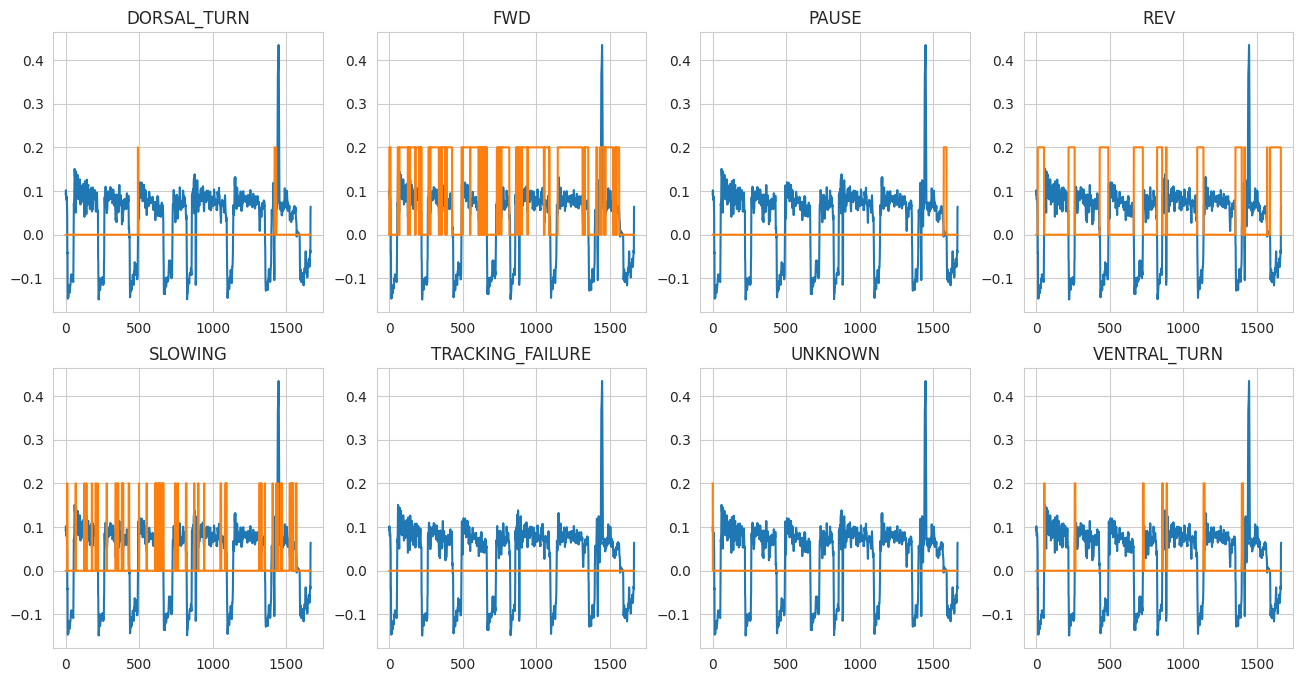

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

velocity = continuous_behaviors['velocity']
x = np.arange(len(velocity))
for i, state in enumerate(discrete_states):
	axes[i // 4, i % 4].plot(x, velocity, x, discrete_states[state] * 0.2)
	axes[i // 4, i % 4].set_title(state)

-0.7530063999757979


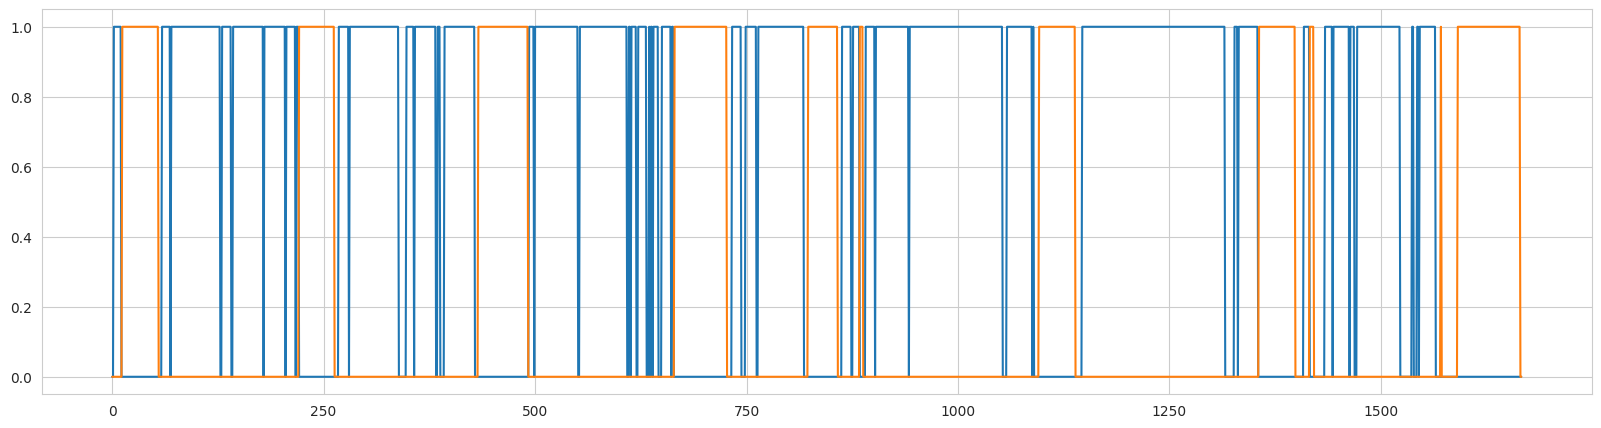

In [7]:
ds1 = discrete_states['FWD']
ds2 = discrete_states['REV']

x = np.arange(len(ds1))
plt.figure(figsize=(20, 5))
plt.plot(x, ds1, x, ds2)

corr = np.corrcoef(ds1, ds2)[0, 1]
print(corr)

nan


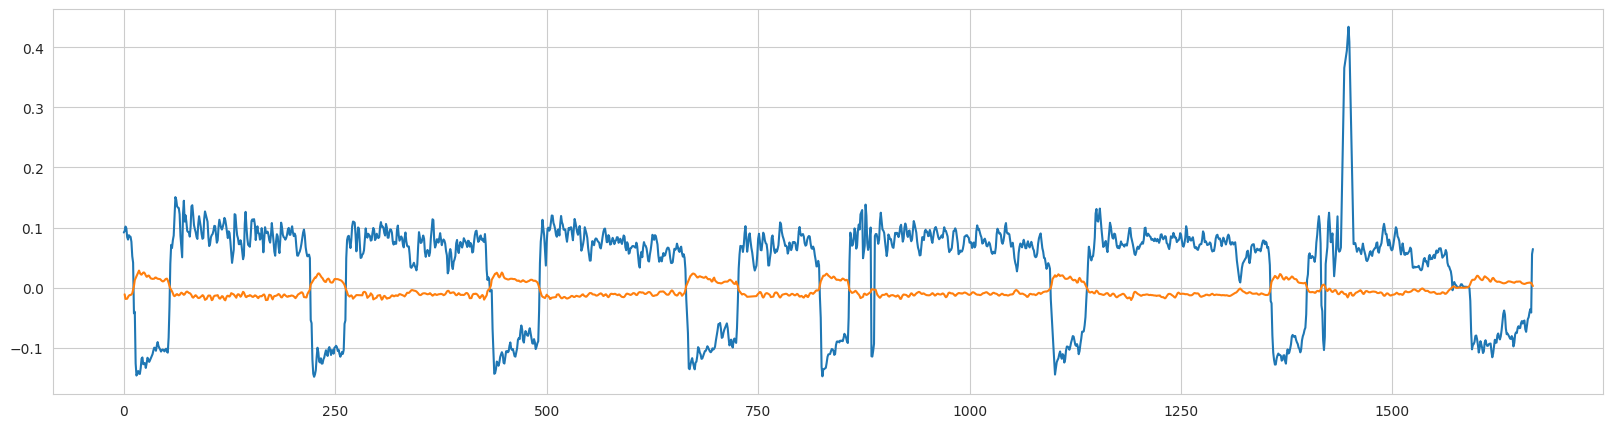

In [8]:
behav1 = continuous_behaviors['velocity']
behav2 = continuous_behaviors['angular_velocity']

x = np.arange(len(behav1))
plt.figure(figsize=(20, 5))
plt.plot(x, behav1, x, behav2)

corr = np.corrcoef(behav1, behav2)[0, 1]
print(corr)

# kymograph bc why not

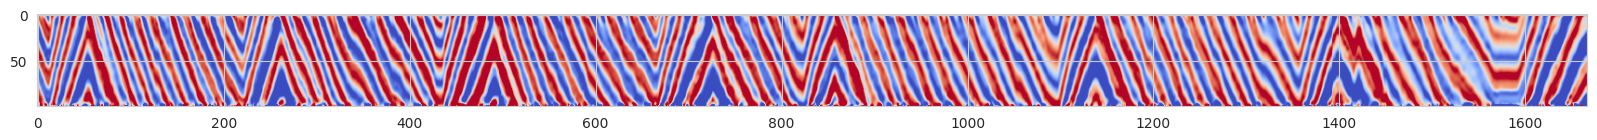

In [9]:
plt.figure(figsize=(20, 100))
plt.imshow(np.clip(kymograph, -0.01, 0.01).T, cmap='coolwarm')